# A/B-тест нового алгоритма рекомендаций

Развлекательное приложение с «бесконечной» лентой коротких видео. Модели монетизации — ежемесячная подписка, отключающая рекламу, и показ рекламы пользователям без подписки.

Команда рекомендательных систем разработала новый алгоритм, который, по её мнению, показывает каждому пользователю более интересный контент. Задача — рассчитать параметры A/B-теста, проверить корректность его проведения и проанализировать результаты.

## Данные

Три таблицы с одинаковой структурой, различаются периодом наблюдения:

- `sessions_project_history.csv` — исторические данные о сессиях пользователей с 2025-08-11 по 2025-09-23;
- `sessions_project_test_part.csv` — данные за первый день A/B-теста, 2025-10-14;
- `sessions_project_test.csv` — данные за весь период A/B-теста, с 2025-10-14 по 2025-11-02.

Поля:

- `user_id` — идентификатор пользователя;
- `session_id` — идентификатор сессии;
- `session_date` — дата сессии;
- `session_start_ts` — дата и время начала сессии;
- `install_date` — дата установки приложения;
- `session_number` — порядковый номер сессии пользователя;
- `registration_flag` — зарегистрирован ли пользователь;
- `page_counter` — количество просмотренных страниц за сессию;
- `region` — регион пользователя;
- `device` — тип устройства;
- `test_group` — группа теста (только в данных теста).

## План работы

1. Исследовательский анализ исторических данных.
2. Подготовка к тесту: целевая метрика, размер выборки, длительность.
3. Мониторинг теста по данным первого дня.
4. Проверка результатов и итоговые выводы.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

In [1]:
# Библиотеки
import os
from math import ceil

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from cycler import cycler
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep

In [2]:
# Путь к данным: на платформе Практикума — /datasets, локально — папка data
DATA_DIR = '/datasets' if os.path.exists('/datasets') else 'data'

# Единая зелёная палитра для всех графиков
plt.rcParams['axes.prop_cycle'] = cycler(color=['#2e7d32', '#81c784'])

# Загружаем исторические данные о сессиях
sessions_history = pd.read_csv(f'{DATA_DIR}/sessions_project_history.csv')

sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными

Считаем число сессий у каждого пользователя и разбираем историю самого активного из них, чтобы понять логику формирования столбцов.

In [3]:
# Считаем число уникальных сессий для каждого пользователя
sessions_per_user = sessions_history.groupby('user_id')['session_id'].nunique()

# Находим пользователя с наибольшим числом сессий
top_user = sessions_per_user.idxmax()

# Смотрим все сессии этого пользователя, чтобы понять логику столбцов
top_user_sessions = sessions_history[sessions_history.user_id == top_user].sort_values('session_number')

display(top_user_sessions)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


**Вывод по 1.2**

На примере самого активного пользователя (10 сессий):

- **Меняются** от сессии к сессии: `session_id`, `session_date`, `session_start_ts`, `session_number` и `page_counter` (от 1 до 4 страниц).
- **Не меняются:** `user_id`, `install_date`, `region` (CIS) и `device` (Android) — это характеристики пользователя, а не сессии.
- `session_date` — дата из `session_start_ts` без времени.
- `session_number` — порядковый номер сессии пользователя. У этого пользователя не больше одной сессии в день, и заходил он не каждый день: 21.08 и 23.08 пропущены.
- `install_date` совпадает с датой первой сессии. *Гипотеза:* дата установки фиксируется по первому запуску приложения.
- `registration_flag` равен 0 во всех 10 сессиях: пользователь активен, но так и не зарегистрировался.

#### 1.3. Анализ числа регистраций

Считаем по дням число активных пользователей, число зарегистрированных среди них (без накопления — аналог DAU для регистраций) и их долю. Для простоты считаем, что у пользователя не больше одной сессии в день и статус регистрации в течение дня не меняется.

In [4]:
# Переводим дату сессии из текста в формат даты — для корректной оси X на графиках
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])

# Для каждого дня считаем число уникальных пользователей и число зарегистрированных
# (по условию у пользователя максимум одна сессия в день, поэтому сумма флагов = число зарегистрированных)
daily_users = sessions_history.groupby('session_date').agg(
    users_count=('user_id', 'nunique'),
    registered_users=('registration_flag', 'sum')
)

# Доля зарегистрированных пользователей от всех активных за день
daily_users['registered_share'] = daily_users['registered_users'] / daily_users['users_count']

display(daily_users)

,users_count,registered_users,registered_share
session_date,,,
2025-08-11,3919,169,0.043123
2025-08-12,6056,336,0.055482
2025-08-13,8489,464,0.054659
2025-08-14,10321,625,0.060556
2025-08-15,14065,840,0.059723
2025-08-16,12205,916,0.075051
2025-08-17,11200,833,0.074375
2025-08-18,10839,860,0.079343
2025-08-19,12118,831,0.068576


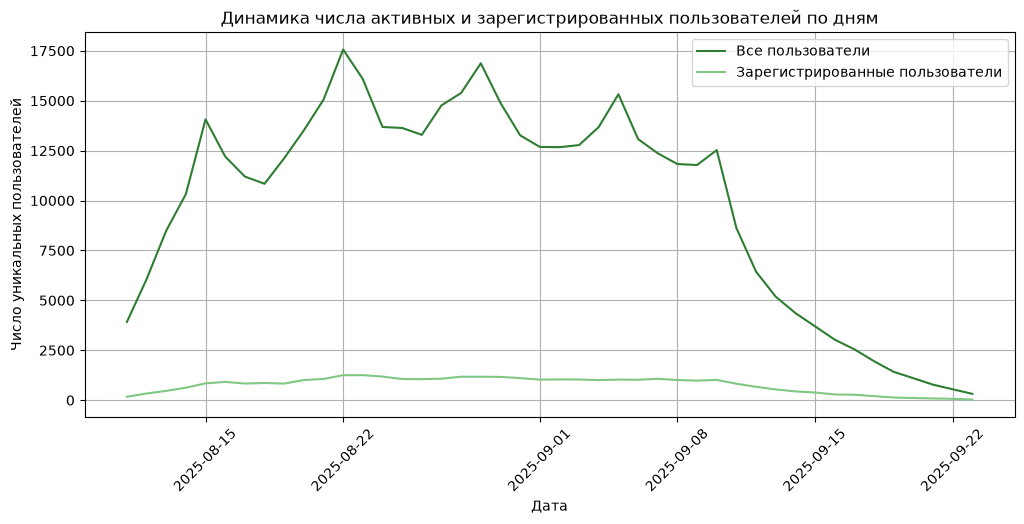

In [5]:
# График 1: общее число пользователей и число зарегистрированных по дням
plt.figure(figsize=(12, 5))

plt.plot(daily_users.index, daily_users['users_count'], label='Все пользователи')
plt.plot(daily_users.index, daily_users['registered_users'], label='Зарегистрированные пользователи')

plt.title('Динамика числа активных и зарегистрированных пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Число уникальных пользователей')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.show()

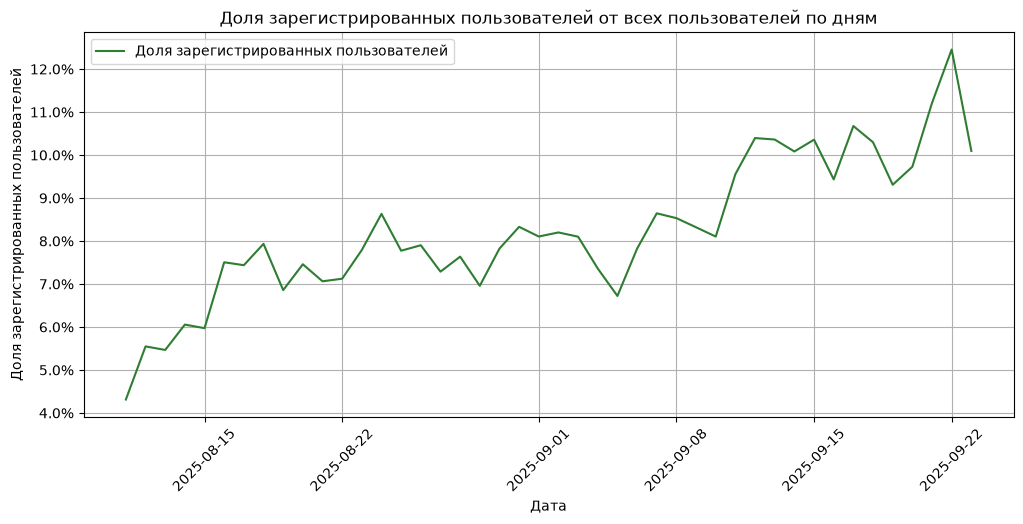

In [6]:
# График 2: доля зарегистрированных пользователей от всех пользователей по дням
plt.figure(figsize=(12, 5))

plt.plot(daily_users.index, daily_users['registered_share'], label='Доля зарегистрированных пользователей')

plt.title('Доля зарегистрированных пользователей от всех пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Доля зарегистрированных пользователей')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

In [7]:
# Проверяем диапазон дат установки в исторических данных
sessions_history['install_date'].min(), sessions_history['install_date'].max()

('2025-08-11', '2025-09-10')

**Вывод по 1.3**

- **Общее число активных пользователей** быстро росло в первые дни: с ~3,9 тыс. 11.08 до пика ~17,5 тыс. 22.08. До 10.09 держалось на уровне 12–16 тыс. в день, затем резко упало: до ~8,6 тыс. 11.09 и до 317 человек к 23.09.
- **Число зарегистрированных пользователей** повторяет форму общей кривой: рост до ~1,25 тыс. в день в конце августа, плато около 1 тыс. и спад после 10.09.
- **Доля зарегистрированных** при этом стабильно растёт: с ~4% в первый день до 7–8% в конце августа и 10–12% в конце периода. Чем дольше пользователи остаются в приложении, тем больше из них регистрируются.
- **Причина спада после 10.09:** в выгрузке есть только пользователи, установившие приложение с 11.08 по 10.09. После 10.09 новые пользователи в данные не попадают, поэтому активность падает за счёт естественного оттока старых. Это особенность выборки, а не реальное падение трафика приложения. По этой же причине доля регистраций в конце периода завышена: остаются самые вовлечённые пользователи.

#### 1.4. Число просмотренных страниц в первой сессии

Чем больше страниц просмотрено, тем сильнее пользователь вовлечён в контент и тем выше шанс, что он зарегистрируется и оформит подписку. Смотрим, сколько первых сессий приходится на каждое число просмотренных страниц.

page_counter
1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: count, dtype: int64

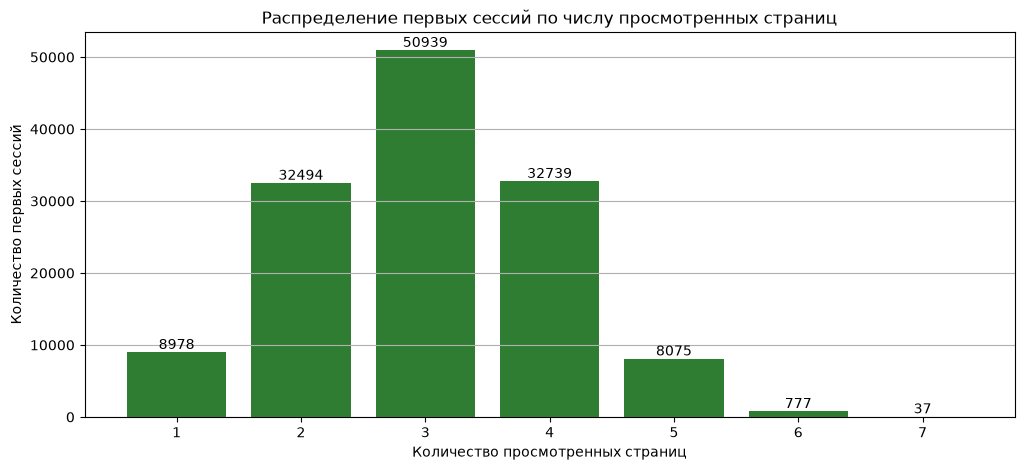

In [8]:
# Оставляем только первые сессии пользователей
first_sessions = sessions_history[sessions_history.session_number == 1]

# Считаем, сколько первых сессий приходится на каждое число просмотренных страниц
pages_distribution = first_sessions['page_counter'].value_counts().sort_index()
display(pages_distribution)

# Столбчатая диаграмма распределения первых сессий по числу просмотренных страниц
plt.figure(figsize=(12, 5))

bars = plt.bar(pages_distribution.index, pages_distribution.values)

plt.bar_label(bars)
plt.title('Распределение первых сессий по числу просмотренных страниц')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество первых сессий')
plt.grid(True, axis='y')   # горизонтальная сетка, чтобы легче читать высоту столбцов
plt.show()

**Вывод по 1.4**

- Распределение первых сессий по числу просмотренных страниц колоколообразное и почти симметричное относительно 3 страниц.
- Чаще всего в первой сессии просматривают **3 страницы** — 50 939 сессий (~38% всех первых сессий). 2 и 4 страницы встречаются примерно одинаково часто — по ~24%.
- Уже после первой страницы заканчивается ~7% первых сессий (8 978).
- Больше 5 страниц смотрят редко: 6 страниц — 777 сессий, 7 страниц (максимум) — всего 37. Длинного «хвоста» нет.

#### 1.5. Доля успешных первых сессий

Продуктовая команда считает первую сессию успешной, если пользователь просмотрел в ней 4 и более страниц: это говорит об удовлетворённости контентом и рекомендациями. Добавляем признак `good_session` и смотрим, как доля успешных первых сессий меняется по дням.

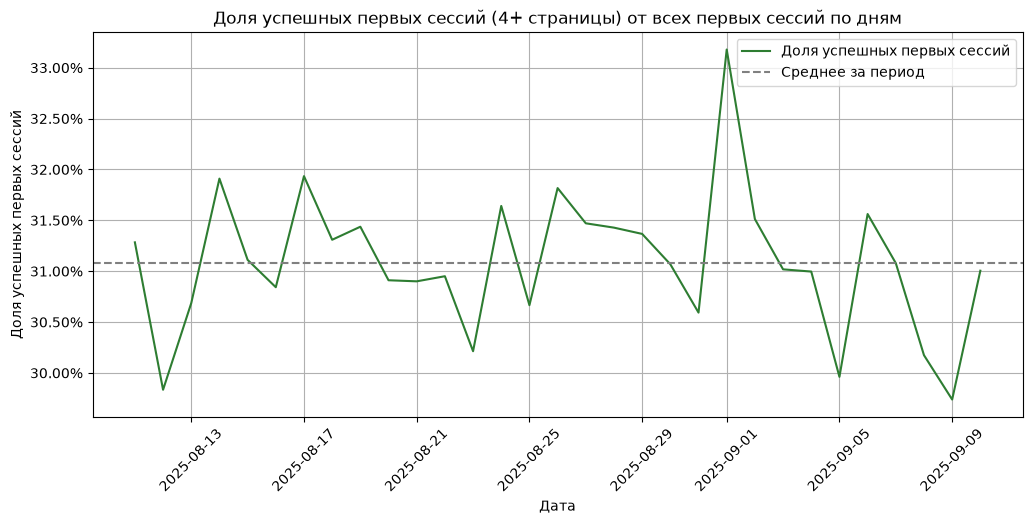

In [9]:
# Помечаем успешные сессии: 1 — если просмотрено 4 и более страниц, иначе 0
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

# Заново отбираем первые сессии — теперь уже с колонкой good_session
first_sessions = sessions_history[sessions_history.session_number == 1]

# Доля успешных первых сессий по дням (среднее от 0/1 = доля единиц)
good_share_daily = first_sessions.groupby('session_date')['good_session'].mean()

# График: доля успешных первых сессий по дням
plt.figure(figsize=(12, 5))

plt.plot(good_share_daily.index, good_share_daily.values, label='Доля успешных первых сессий')
plt.axhline(good_share_daily.mean(), linestyle='--', color='gray', label='Среднее за период')

plt.title('Доля успешных первых сессий (4+ страницы) от всех первых сессий по дням')
plt.xlabel('Дата')
plt.ylabel('Доля успешных первых сессий')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

**Вывод по 1.5**

- В среднем за период **~31,1%** первых сессий — успешные (4 и более просмотренных страниц).
- Метрика стабильна: по дням она колеблется примерно от 29,7% до 33,2%, то есть отклоняется от среднего не более чем на ~2 п.п. Выраженного тренда вверх или вниз нет. Визуально скачки кажутся крупнее из-за масштаба оси Y (она начинается не с нуля).
- Наибольшее значение — 01.09 (~33,2%), наименьшее — 09.09 (~29,7%).
- Данные по первым сессиям заканчиваются 10.09 — после этой даты в выгрузке нет новых установок (см. 1.3).
- Стабильный базовый уровень ~31% удобен для A/B-теста: на его фоне будет проще заметить эффект нового алгоритма рекомендаций.

### 2. Подготовка к тесту

Определяем целевую метрику, рассчитываем необходимый размер выборки и длительность теста при текущем трафике.

#### 2.1. Расчёт размера выборки

Параметры: уровень значимости α = 0,05, вероятность ошибки второго рода β = 0,2 (мощность 0,8), базовый уровень доли успешных первых сессий — 0,3, минимальный детектируемый эффект (MDE) — 3 п.п. Размер выборки рассчитываем методом `solve_power()` класса `NormalIndPower` из `statsmodels`.

In [10]:
# Параметры расчёта
alpha = 0.05       # уровень значимости
beta = 0.2         # вероятность ошибки второго рода
power = 1 - beta   # мощность теста
p = 0.3            # базовый уровень доли успешных первых сессий
mde = 0.03         # минимальный детектируемый эффект — относительный рост на 3%

# Переводим относительный MDE в целевое значение доли: 0.30 * 1.03 = 0.309
p2 = p * (1 + mde)
effect_size = proportion_effectsize(p, p2)

# Расчёт размера выборки для одной группы
power_analysis = NormalIndPower()
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1  # группы одинакового размера
)

# Размер выборки округляем вверх
sample_size = ceil(sample_size)
print(f'Целевая доля успешных первых сессий: {p2:.3f} (рост на {(p2 - p) * 100:.1f} п.п.)')
print(f'Необходимый размер выборки для каждой группы: {sample_size}')

Целевая доля успешных первых сессий: 0.309 (рост на 0.9 п.п.)
Необходимый размер выборки для каждой группы: 41041


#### 2.2. Расчёт длительности A/B-теста

Длительность = суммарный размер выборки двух групп / среднее число уникальных пользователей в день, с округлением вверх.

In [11]:
# Среднее количество уникальных пользователей приложения в день по историческим данным
avg_daily_users = daily_users['users_count'].mean()

# Длительность теста: суммарный размер двух групп делим на дневной трафик и округляем вверх
test_duration = ceil(sample_size * 2 / avg_daily_users)

print(f'Среднее число уникальных пользователей в день: {avg_daily_users:.0f}')
print(f'Рассчитанная длительность A/B-теста: {test_duration} дн.')

# Метрика считается по первым сессиям, то есть в тест попадают только новые пользователи.
# Оценим длительность и по среднему дневному притоку новых пользователей
avg_daily_new_users = first_sessions.groupby('session_date')['user_id'].nunique().mean()
test_duration_new = ceil(sample_size * 2 / avg_daily_new_users)

print(f'Среднее число новых пользователей в день: {avg_daily_new_users:.0f}')
print(f'Длительность набора выборки из новых пользователей: {test_duration_new} дн.')

Среднее число уникальных пользователей в день: 9907
Рассчитанная длительность A/B-теста: 9 дн.
Среднее число новых пользователей в день: 4324
Длительность набора выборки из новых пользователей: 19 дн.


**Вывод по разделу 2. Подготовка к тесту**

- **Целевая метрика** — доля успешных первых сессий (4 и более просмотренных страниц). По историческим данным её базовый уровень ~30–31%.
- **Минимальный детектируемый эффект** — относительный рост доли на 3%: с 30% до 30,9%, то есть на 0,9 п.п.
- **Размер выборки:** при уровне значимости α = 0,05 и мощности 0,8 необходимо **41 041 пользователь в каждую группу**, всего 82 082.
- **Длительность:** при среднем трафике ~9 907 уникальных пользователей в день расчётная длительность теста — **9 дней**.
- **Ограничения расчёта:** метрика считается по первым сессиям, поэтому в тест попадают только новые пользователи, а средний трафик учитывает всех активных. Новых пользователей в среднем ~4 300 в день, и набор нужной выборки займёт около **19 дней**. Кроме того, тест должен охватывать полные недели, чтобы учесть различия в поведении пользователей в будни и выходные.

### 3. Мониторинг A/B-теста

По данным первого дня теста (14.10.2025) проверяем, что пользователи распределены по группам корректно.

#### 3.1. Размер групп

Сравниваем число уникальных пользователей в группах и считаем процентную разницу:

$$P = 100 \cdot \frac{|A - B|}{A}$$

test_group
A    1477
B    1466
Name: user_id, dtype: int64

Процентная разница в количестве пользователей в группах: 0.74%


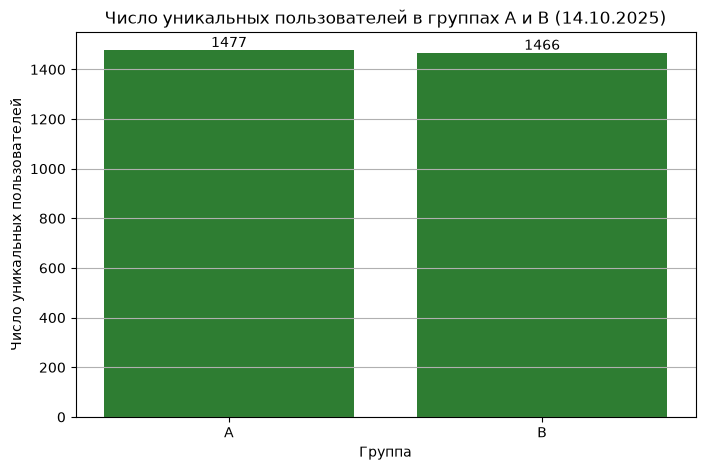

In [12]:
# Загружаем данные за первый день теста
sessions_test_part = pd.read_csv(f'{DATA_DIR}/sessions_project_test_part.csv')

# Считаем уникальных пользователей в каждой группе
test_users_count = sessions_test_part.groupby('test_group')['user_id'].nunique()
display(test_users_count)

# Процентная разница по формуле P = 100 * |A - B| / A
percent_dif = 100 * abs(test_users_count['A'] - test_users_count['B']) / test_users_count['A']
print(f'Процентная разница в количестве пользователей в группах: {percent_dif:.2f}%')

# Столбчатая диаграмма числа уникальных пользователей в группах A и B
plt.figure(figsize=(8, 5))

bars = plt.bar(test_users_count.index, test_users_count.values)
plt.bar_label(bars)

plt.title('Число уникальных пользователей в группах A и B (14.10.2025)')
plt.xlabel('Группа')
plt.ylabel('Число уникальных пользователей')
plt.grid(True, axis='y')
plt.show()

#### 3.2. Пересечение групп

Проверяем, что ни один пользователь не попал одновременно в обе группы.

In [13]:
# Уникальные пользователи каждой группы
users_a = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'])
users_b = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'])

# Пользователи, которые попали в обе группы одновременно
intersection = users_a & users_b
print(f'Пользователей, попавших в обе группы: {len(intersection)}')

Пользователей, попавших в обе группы: 0


#### 3.3. Распределение пользователей по устройствам

Сравниваем доли типов устройств в группах A и B. Доли считаем по уникальным пользователям, а не по сессиям.

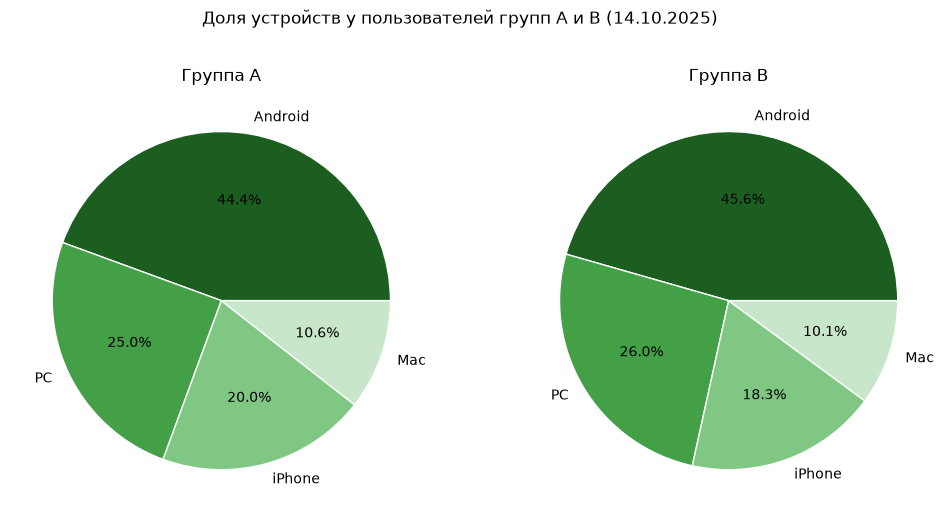

In [14]:
# Пользователи каждой группы (по одной строке на пользователя — считаем людей, а не сессии)
group_a = sessions_test_part[sessions_test_part['test_group'] == 'A'].drop_duplicates(subset='user_id')
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B'].drop_duplicates(subset='user_id')

# Доля каждого типа устройства в группе (normalize=True — доли вместо количества)
devices_a = group_a['device'].value_counts(normalize=True)
devices_b = group_b['device'].value_counts(normalize=True)

# Единый порядок устройств и закреплённый цвет за каждым — чтобы диаграммы A и B было легко сравнивать
device_order = ['Android', 'PC', 'iPhone', 'Mac']
device_colors = ['#1b5e20', '#43a047', '#81c784', '#c8e6c9']

devices_a = devices_a.reindex(device_order)
devices_b = devices_b.reindex(device_order)

# Две круговые диаграммы рядом: слева группа A, справа группа B
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].pie(devices_a.values, labels=devices_a.index, colors=device_colors,
            autopct='%1.1f%%', wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Группа A')

axes[1].pie(devices_b.values, labels=devices_b.index, colors=device_colors,
            autopct='%1.1f%%', wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Группа B')

fig.suptitle('Доля устройств у пользователей групп A и B (14.10.2025)')
plt.show()

#### 3.4. Распределение пользователей по регионам

Аналогично сравниваем доли регионов в группах.

,Группа A,Группа B
region,,
CIS,0.436019,0.439973
MENA,0.412322,0.412005
EU,0.151659,0.148022


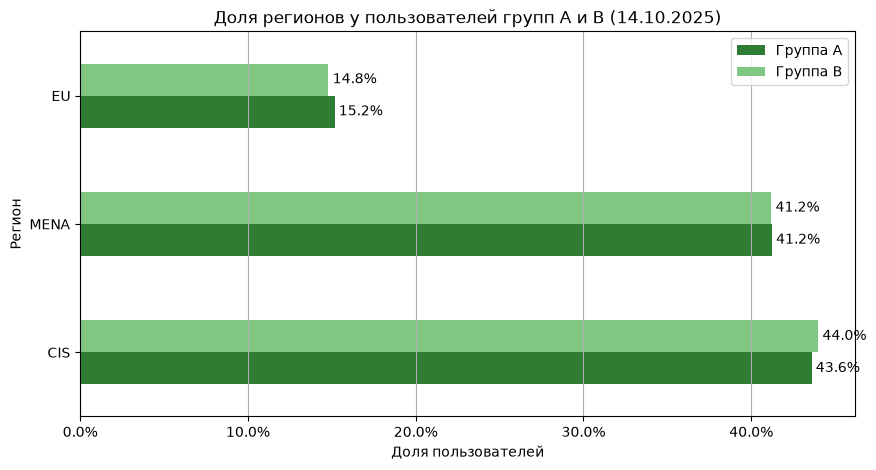

In [15]:
# Доля каждого региона в группе (normalize=True — доли вместо количества)
regions_a = group_a['region'].value_counts(normalize=True)
regions_b = group_b['region'].value_counts(normalize=True)

# Собираем доли обеих групп в одну таблицу: строки — регионы, колонки — группы
regions_share = pd.DataFrame({'Группа A': regions_a, 'Группа B': regions_b})
display(regions_share)

# Сгруппированная горизонтальная столбчатая диаграмма: для каждого региона два столбца — A и B
ax = regions_share.plot(kind='barh', figsize=(10, 5))

for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)   # подписи долей в процентах

ax.set_title('Доля регионов у пользователей групп A и B (14.10.2025)')
ax.set_xlabel('Доля пользователей')
ax.set_ylabel('Регион')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(True, axis='x')
plt.show()

#### 3.5. Вывод по мониторингу теста

**Вывод по 3. Мониторинг A/B-теста (первый день, 14.10.2025)**

- **Размер групп.** В группе A — 1 477 уникальных пользователей, в группе B — 1 466. Разница составляет 0,74%, что говорит о равномерном разделении трафика.
- **Независимость выборок.** Пользователей, попавших одновременно в обе группы, не обнаружено — группы независимы.
- **Распределение по устройствам** в группах практически совпадает: Android — 44,4% и 45,6%, PC — 25,0% и 26,0%, iPhone — 20,0% и 18,3%, Mac — 10,6% и 10,1%. Расхождения не превышают ~2 п.п.
- **Распределение по регионам** также совпадает: CIS — 43,6% и 44,0%, MENA — 41,2% и 41,2%, EU — 15,2% и 14,8%.
- Доли считались по уникальным пользователям: часть пользователей совершила за день несколько сессий, и расчёт по сессиям искажал бы структуру групп.

**Заключение:** нарушений не выявлено — группы сопоставимы по размеру, не пересекаются и однородны по устройствам и регионам. A/B-тест проходит корректно, можно продолжать сбор данных.

### 4. Проверка результатов A/B-теста

Тест завершён — анализируем данные за весь период эксперимента.

#### 4.1. Данные за весь период теста

Загружаем результаты и добавляем признак успешной сессии `good_session`.

In [16]:
# Загружаем данные за весь период A/B-теста
sessions_test = pd.read_csv(f'{DATA_DIR}/sessions_project_test.csv')

# Помечаем успешные сессии: 1 — если просмотрено 4 и более страниц, иначе 0
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2. Гипотезы и метрики

**Целевая метрика:** доля успешных первых сессий — первых сессий, в которых пользователь просмотрел 4 и более страниц.

**Гипотезы** (уровень значимости α = 0,05):
- **H₀:** доля успешных первых сессий в тестовой группе B равна доле в контрольной группе A.
- **H₁:** доля успешных первых сессий в группе B больше, чем в группе A — новый алгоритм рекомендаций показывает более интересный контент.

Поскольку ожидается именно рост метрики, используем односторонний (правосторонний) тест.

**Прокси-метрики** (быстрые сигналы вовлечённости):
- среднее число просмотренных страниц в первой сессии;
- средняя длительность первой сессии;
- доля пользователей, вернувшихся в приложение на следующий день после установки.

**Барьерные метрики** (не должны ухудшиться):
- доля регистраций среди новых пользователей;
- конверсия в платную подписку;
- число показов рекламы на пользователя без подписки — выручка от рекламы;
- технические показатели: время загрузки ленты, доля сбоев приложения.

#### 4.3. Сравнение доли успешных первых сессий

Считаем долю успешных первых сессий в группах A и B и разницу между ними.

In [17]:
# Первые сессии пользователей каждой группы
first_a = sessions_test[(sessions_test['test_group'] == 'A') & (sessions_test['session_number'] == 1)]
first_b = sessions_test[(sessions_test['test_group'] == 'B') & (sessions_test['session_number'] == 1)]

# Доля успешных первых сессий (среднее от 0/1 = доля единиц)
share_a = first_a['good_session'].mean()
share_b = first_b['good_session'].mean()

# Разница B − A в процентных пунктах (знак показывает направление)
difference = (share_b - share_a) * 100

print(f'Доля успешных первых сессий в группе A: {share_a:.2%}')
print(f'Доля успешных первых сессий в группе B: {share_b:.2%}')
print(f'Разница (B − A): {difference:.2f} п.п.')

# Число уникальных пользователей в группах за весь период теста
display(sessions_test.groupby('test_group')['user_id'].nunique())

Доля успешных первых сессий в группе A: 31.57%
Доля успешных первых сессий в группе B: 31.47%
Разница (B − A): -0.11 п.п.


test_group
A    15163
B    15416
Name: user_id, dtype: int64

#### 4.4. Статистическая значимость изменения

Проверяем, значима ли разница, с помощью z-теста для долей (α = 0,05).

In [18]:
# Z-тест для долей: проверяем, что доля успешных первых сессий в B больше, чем в A
alpha = 0.05  # уровень значимости

# Число успешных первых сессий и общее число первых сессий в каждой группе (B — первой, т.к. H1: B > A)
successes = [first_b['good_session'].sum(), first_a['good_session'].sum()]
observations = [len(first_b), len(first_a)]

stat_ztest, p_value_ztest = proportions_ztest(successes, observations, alternative='larger')

print(f'z-статистика: {stat_ztest:.3f}')
print(f'p-value: {p_value_ztest:.4f}')

if p_value_ztest < alpha:
    print('Отвергаем нулевую гипотезу: доля успешных первых сессий в группе B статистически значимо больше, чем в A.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу: статистически значимого роста доли успешных первых сессий в группе B не обнаружено.')

z-статистика: -0.198
p-value: 0.5784
Нет оснований отвергнуть нулевую гипотезу: статистически значимого роста доли успешных первых сессий в группе B не обнаружено.


**Дополнительно: чувствительность теста**

Размер выборки пересчитан под относительный MDE, поэтому проверим, хватило ли фактического объёма данных, и оценим доверительный интервал разницы долей.

In [19]:
# Какую долю от необходимого размера выборки удалось набрать в каждой группе
print(f'Первых сессий в группе A: {len(first_a)} — {len(first_a) / sample_size:.0%} от необходимых {sample_size}')
print(f'Первых сессий в группе B: {len(first_b)} — {len(first_b) / sample_size:.0%} от необходимых {sample_size}')

# 95%-й доверительный интервал разницы долей успешных первых сессий (B − A)
ci_low, ci_high = confint_proportions_2indep(
    first_b['good_session'].sum(), len(first_b),
    first_a['good_session'].sum(), len(first_a),
    compare='diff', method='wald'
)
print(f'95%-й доверительный интервал разницы (B − A): от {ci_low * 100:.2f} до {ci_high * 100:.2f} п.п.')
print(f'Целевой эффект (MDE): +{(p2 - p) * 100:.1f} п.п.')

Первых сессий в группе A: 15162 — 37% от необходимых 41041
Первых сессий в группе B: 15416 — 38% от необходимых 41041
95%-й доверительный интервал разницы (B − A): от -1.15 до 0.94 п.п.
Целевой эффект (MDE): +0.9 п.п.


#### 4.5. Итоговый вывод

**Вывод по результатам A/B-эксперимента**

**Характеристики эксперимента.** Тест проводился с 14.10 по 02.11.2025 (20 дней); новые пользователи набирались в тест с 14.10 по 20.10. В эксперименте участвовали 30 579 пользователей: 15 163 в контрольной группе A и 15 416 в тестовой группе B. Мониторинг первого дня показал, что группы сопоставимы по размеру, не пересекаются и однородны по устройствам и регионам.

**Размер выборки.** Чтобы обнаружить относительный рост доли успешных первых сессий на 3% (с 30% до 30,9%), требовалось 41 041 пользователь в каждую группу. Фактически в группах набрано около 37% от этого объёма, поэтому тест недостаточно чувствителен, чтобы надёжно обнаружить эффект заложенного размера.

**Влияние на ключевую метрику.** Доля успешных первых сессий (4 и более просмотренных страниц) составила 31,57% в группе A и 31,47% в группе B — разница −0,11 п.п. Роста метрики в тестовой группе не наблюдается: показатель в группе B даже незначительно ниже.

**Статистическая значимость.** Односторонний z-тест для долей (H₁: доля в B больше, чем в A) дал z = −0,198 и **p-value = 0,578**, что значительно выше уровня значимости 0,05. Оснований отвергнуть нулевую гипотезу нет — статистически значимого улучшения ключевой метрики не обнаружено. При этом 95%-й доверительный интервал разницы долей — от −1,15 до +0,94 п.п.: он включает и ноль, и целевой эффект +0,9 п.п. По имеющимся данным рост на 3% нельзя ни подтвердить, ни исключить.

**Рекомендация.** Внедрять новый алгоритм рекомендаций в текущем виде не стоит: данных в пользу улучшения нет, а точечная оценка даже немного ниже контрольной группы. Если рост ключевой метрики на 3% важен для бизнеса, тест стоит продлить или перезапустить так, чтобы набрать около 41 тыс. новых пользователей в каждую группу (порядка 19 дней набора при текущем притоке). Параллельно команде разработки стоит проверить прокси-метрики (например, среднее число страниц в первой сессии) и отдельные сегменты (устройства, регионы) — возможно, эффект проявляется только на части аудитории.